In [1]:
%pip install pandas openpyxl pyarrow matplotlib seaborn

  Using cached pandas-3.0.6-cp313-cp313-macosx_10_13_x86_64.whl.metadata (79 kB)
  Using cached matplotlib-3.11.2-cp313-cp313-macosx_10_13_x86_64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached numpy-2.5.4-cp313-cp313-macosx_14_0_x86_64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp313-cp313-macosx_10_13_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp313-cp313-macosx_10_13_x86_64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached pandas-3.0.6-cp313-cp313-macosx_10_13_x86_64.whl (10.4 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.7/38.7 MB 36.7 MB/s  0:00:01m0:00:0100:01
Using cached matplotlib-3.11.2-cp313-cp313-macosx_10_13_x86_64.whl (9.5 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached contourpy-1.4.0-cp313-cp313-macosx_10_13_x86_64.whl (297 kB)
Using cached cycler-0.

In [ ]:
import pandas as pd

sheets = pd.read_excel("../data/raw/online_retail_II.xlsx", sheet_name=None)
df = pd.concat(sheets.values(), ignore_index=True)

df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["Description"] = df["Description"].astype("string")

df.to_parquet("../data/raw/online_retail_II.parquet", index=False)

ArrowTypeError: ("Expected bytes, got a 'int' object", 'Conversion failed for column Description with type object')

In [3]:
print(df.shape)
print(df.dtypes)
print(df.isna().sum())

print("Cancellations:", df["Invoice"].str.startswith("C").sum())
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("Price <= 0:", (df["Price"] <= 0).sum())
print("Date range:", df["InvoiceDate"].min(), "to", df["InvoiceDate"].max())
print("Unique customers:", df["Customer ID"].nunique())
print("Exact duplicates:", df.duplicated().sum())

(1067371, 8)
Invoice                   str
StockCode                 str
Description            string
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object
Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Cancellations: 19494
Quantity <= 0: 22950
Price <= 0: 6207
Date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00
Unique customers: 5942
Exact duplicates: 34335


In [4]:
# Stock codes that aren't the normal 5-digit product format (optionally with a letter suffix)
odd_codes = df[~df["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")]
print(odd_codes["StockCode"].value_counts().head(30))

StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
gift_0001_10      16
CRUK              16
DCGS0076          15
TEST001           15
DCGS0003          14
gift_0001_50       8
gift_0001_40       7
DCGS0069           6
B                  6
DCGS0004           5
m                  5
gift_0001_80       4
DCGS0072           4
DCGS0066N          4
DCGS0068           3
Name: count, dtype: int64


In [5]:
check = df[df["StockCode"].str.startswith(("DCGS", "M", "PADS"))]
print(check.groupby("StockCode")["Description"].first().head(20))

StockCode
DCGS0003                  BOXED GLASS ASHTRAY
DCGS0004           HAYNES CAMPER SHOULDER BAG
DCGS0006                                 <NA>
DCGS0016                                 <NA>
DCGS0027                                 <NA>
DCGS0036                                 <NA>
DCGS0037                   KEY-RING CORKSCREW
DCGS0039                                 <NA>
DCGS0041     HAYNES MINI-COOPER PLAYING CARDS
DCGS0044              HANDZ-OFF CAR FRESHENER
DCGS0053                                 <NA>
DCGS0055                                 <NA>
DCGS0056                                 <NA>
DCGS0057                                 <NA>
DCGS0058                     MISO PRETTY  GUM
DCGS0059                                 <NA>
DCGS0060                                 <NA>
DCGS0062              ROAD-RAGE CAR FRESHENER
DCGS0066N             NAVY CUDDLES DOG HOODIE
DCGS0066P                                <NA>
Name: Description, dtype: string


In [6]:
clean = df.drop_duplicates().copy()
log = [("Raw rows", len(df)), ("After dropping exact duplicates", len(clean))]

# Keep real products: 5-digit codes (optional letter suffix) plus DCGS codes
is_product = (
    clean["StockCode"].str.match(r"^\d{5}[A-Za-z]*$")
    | clean["StockCode"].str.startswith("DCGS")
)
clean = clean[is_product].copy()
log.append(("After dropping non-product codes", len(clean)))

clean["Revenue"] = clean["Quantity"] * clean["Price"]

# How much do we lose by dropping rows without a customer?
missing_id = clean["Customer ID"].isna()
print(f"Rows missing Customer ID: {missing_id.mean():.1%}")
print(f"Revenue on rows missing Customer ID: "
      f"{clean.loc[missing_id, 'Revenue'].sum() / clean['Revenue'].sum():.1%}")

clean = clean[~missing_id].copy()
clean["Customer ID"] = clean["Customer ID"].astype("int64")
log.append(("After dropping missing Customer ID", len(clean)))

# Split cancellations from purchases
is_cancel = clean["Invoice"].str.startswith("C")
cancellations = clean[is_cancel].copy()
purchases = clean[~is_cancel & (clean["Quantity"] > 0) & (clean["Price"] > 0)].copy()
log.append(("Purchase rows", len(purchases)))
log.append(("Cancellation rows", len(cancellations)))

for step, rows in log:
    print(f"{step:<40}{rows:>12,}")

Rows missing Customer ID: 22.7%
Revenue on rows missing Customer ID: 13.6%
Raw rows                                   1,067,371
After dropping exact duplicates            1,033,036
After dropping non-product codes           1,027,212
After dropping missing Customer ID           794,223
Purchase rows                                776,577
Cancellation rows                             17,586


In [7]:
purchases["InvoiceMonth"] = purchases["InvoiceDate"].dt.to_period("M")

# Each customer's cohort = the month of their first purchase
purchases["CohortMonth"] = (
    purchases.groupby("Customer ID")["InvoiceMonth"].transform("min")
)

# Months since first purchase (0 = the month they were acquired)
purchases["CohortIndex"] = (
    (purchases["InvoiceMonth"].dt.year - purchases["CohortMonth"].dt.year) * 12
    + (purchases["InvoiceMonth"].dt.month - purchases["CohortMonth"].dt.month)
)

print(purchases[["Customer ID", "InvoiceMonth", "CohortMonth", "CohortIndex"]].head(10))
print("\nNew customers per cohort:")
print(purchases.groupby("CohortMonth")["Customer ID"].nunique())

   Customer ID InvoiceMonth CohortMonth  CohortIndex
0        13085      2009-12     2009-12            0
1        13085      2009-12     2009-12            0
2        13085      2009-12     2009-12            0
3        13085      2009-12     2009-12            0
4        13085      2009-12     2009-12            0
5        13085      2009-12     2009-12            0
6        13085      2009-12     2009-12            0
7        13085      2009-12     2009-12            0
8        13085      2009-12     2009-12            0
9        13085      2009-12     2009-12            0

New customers per cohort:
CohortMonth
2009-12    951
2010-01    368
2010-02    375
2010-03    441
2010-04    294
2010-05    255
2010-06    267
2010-07    185
2010-08    163
2010-09    239
2010-10    375
2010-11    326
2010-12     76
2011-01     72
2011-02    125
2011-03    179
2011-04    106
2011-05    111
2011-06    108
2011-07    101
2011-08    107
2011-09    188
2011-10    221
2011-11    191
2011-12     28
Fre

In [8]:
cutoff = pd.Period("2011-12", freq="M")
retention_data = purchases[purchases["InvoiceMonth"] < cutoff]

# Count active customers for each cohort in each month since acquisition
cohort_counts = (
    retention_data.groupby(["CohortMonth", "CohortIndex"])["Customer ID"]
    .nunique()
    .unstack()
)

# Divide each row by its month-0 size to get retention rates
cohort_sizes = cohort_counts[0]
retention = cohort_counts.divide(cohort_sizes, axis=0)

print(retention.round(2).iloc[:, :7])

CohortIndex    0     1     2     3     4     5     6
CohortMonth                                         
2009-12      1.0  0.35  0.33  0.42  0.38  0.36  0.38
2010-01      1.0  0.21  0.32  0.32  0.27  0.31  0.27
2010-02      1.0  0.23  0.23  0.29  0.25  0.20  0.19
2010-03      1.0  0.19  0.23  0.24  0.23  0.20  0.25
2010-04      1.0  0.19  0.19  0.16  0.18  0.22  0.28
2010-05      1.0  0.16  0.17  0.18  0.18  0.25  0.21
2010-06      1.0  0.18  0.19  0.21  0.23  0.28  0.13
2010-07      1.0  0.16  0.18  0.30  0.29  0.14  0.11
2010-08      1.0  0.20  0.29  0.33  0.17  0.12  0.10
2010-09      1.0  0.23  0.23  0.13  0.09  0.10  0.14
2010-10      1.0  0.26  0.15  0.13  0.09  0.08  0.13
2010-11      1.0  0.17  0.10  0.10  0.08  0.09  0.13
2010-12      1.0  0.09  0.05  0.09  0.12  0.07  0.05
2011-01      1.0  0.17  0.22  0.19  0.22  0.15  0.15
2011-02      1.0  0.16  0.16  0.18  0.22  0.16  0.16
2011-03      1.0  0.18  0.22  0.20  0.22  0.15  0.21
2011-04      1.0  0.25  0.20  0.20  0.18  0.24

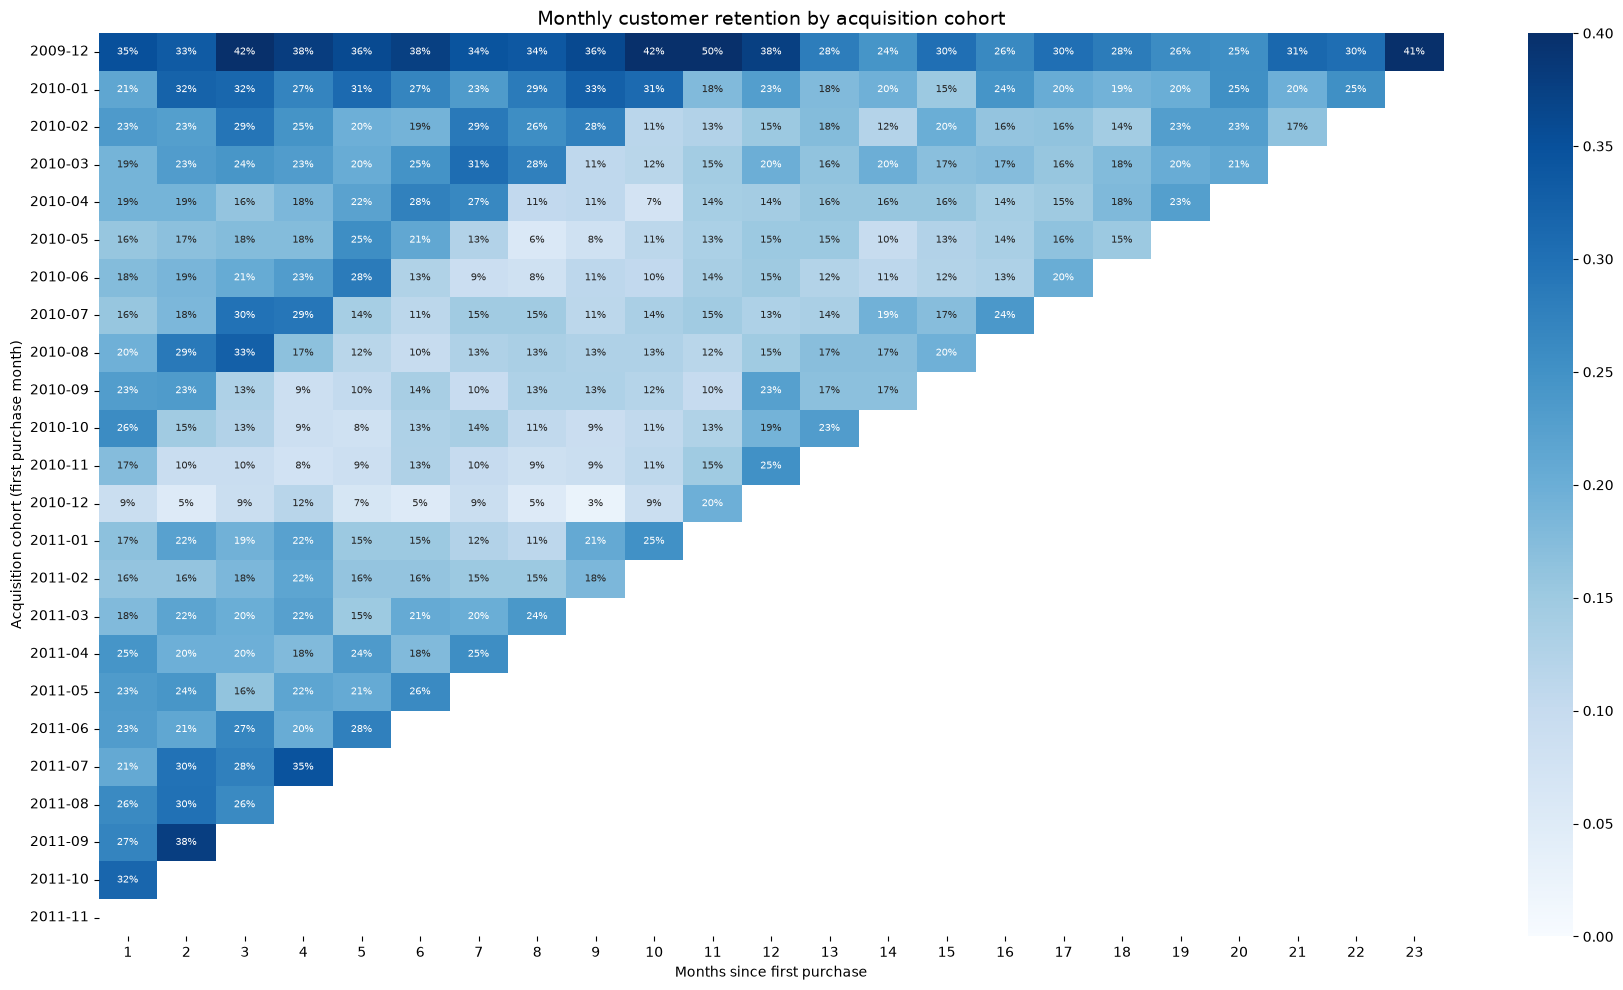

In [9]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("../images", exist_ok=True)

fig, ax = plt.subplots(figsize=(18, 10))
sns.heatmap(
    retention.drop(columns=0),
    annot=True,
    fmt=".0%",
    annot_kws={"size": 7},
    cmap="Blues",
    vmin=0,
    vmax=0.4,
    ax=ax,
)
ax.set_title("Monthly customer retention by acquisition cohort", fontsize=14)
ax.set_xlabel("Months since first purchase")
ax.set_ylabel("Acquisition cohort (first purchase month)")
plt.tight_layout()
fig.savefig("../images/retention_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
# "Today" for the analysis = the day after the last transaction in the data
snapshot = purchases["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = purchases.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
)
rfm["Recency"] = (snapshot - rfm["LastPurchase"]).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]]

print(rfm.head())
print(rfm.describe().round(1))

             Recency  Frequency  Monetary
Customer ID                              
12346            326          3  77352.96
12347              2          8   4921.53
12348             75          5   1658.40
12349             19          3   3678.69
12350            310          1    294.40
       Recency  Frequency  Monetary
count   5852.0     5852.0    5852.0
mean     200.2        6.3    2916.7
std      208.5       12.7   14306.9
min        1.0        1.0       3.0
25%       25.0        1.0     339.6
50%       95.0        3.0     856.0
75%      379.0        7.0    2241.0
max      739.0      373.0  580987.0


In [11]:
print(cancellations.loc[cancellations["Customer ID"] == 12346, "Revenue"].sum())

-77183.6


In [12]:
net_cancel = cancellations.groupby("Customer ID")["Revenue"].sum()  # negative values
rfm["Monetary"] = rfm["Monetary"] + net_cancel.reindex(rfm.index, fill_value=0)

print("Customers with net Monetary <= 0:", (rfm["Monetary"] <= 0).sum())
print(rfm["Monetary"].describe().round(1))

Customers with net Monetary <= 0: 19
count      5852.0
mean       2795.6
std       13825.3
min       -1343.2
25%         330.9
50%         840.2
75%        2172.0
max      578408.6
Name: Monetary, dtype: float64


In [13]:
rfm = rfm[rfm["Monetary"] > 0].copy()
print("Customers scored:", len(rfm))

# Recency: fewer days = better, so the labels run backwards
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# Frequency: many customers tie at 1 order, so rank first to break ties
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

print(rfm.head())
print(rfm[["R", "F", "M"]].apply(pd.Series.value_counts))

Customers scored: 5833
             Recency  Frequency  Monetary  R  F  M
Customer ID                                       
12346            326          3    169.36  2  3  1
12347              2          8   4921.53  5  4  5
12348             75          5   1658.40  3  4  4
12349             19          3   3654.54  5  3  5
12350            310          1    294.40  2  1  2
      R     F     M
1  1164  1167  1167
2  1167  1166  1166
3  1144  1167  1167
4  1172  1166  1166
5  1186  1167  1167


In [14]:
def rfm_segment(row):
    r, f = row["R"], row["F"]
    if r == 5 and f >= 4:
        return "Champions"
    elif r >= 3 and f >= 4:
        return "Loyal"
    elif r >= 4 and f >= 2:
        return "Potential Loyalists"
    elif r == 5 and f == 1:
        return "New Customers"
    elif r == 4 and f == 1:
        return "Promising"
    elif r == 3 and f == 3:
        return "Need Attention"
    elif r == 3 and f <= 2:
        return "About to Sleep"
    elif r <= 2 and f == 5:
        return "Can't Lose Them"
    elif r <= 2 and f >= 3:
        return "At Risk"
    else:
        return "Hibernating"

rfm["Segment"] = rfm.apply(rfm_segment, axis=1)

seg_summary = rfm.groupby("Segment").agg(
    Customers=("R", "size"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgMonetary=("Monetary", "mean"),
    TotalRevenue=("Monetary", "sum"),
)
seg_summary["PctCustomers"] = seg_summary["Customers"] / seg_summary["Customers"].sum()
seg_summary["PctRevenue"] = seg_summary["TotalRevenue"] / seg_summary["TotalRevenue"].sum()
seg_summary = seg_summary.sort_values("TotalRevenue", ascending=False)

print(seg_summary.round(2))

                     Customers  AvgRecency  AvgFrequency  AvgMonetary  \
Segment                                                                 
Champions                  833        8.59         19.22     10302.48   
Loyal                     1142       66.39          9.78      3957.68   
At Risk                    753      370.50          3.92      1268.53   
Potential Loyalists        717       25.77          2.59       879.97   
Hibernating               1506      456.25          1.25       404.55   
Can't Lose Them             72      327.25         16.36      6648.12   
Need Attention             265      112.40          3.15      1250.04   
About to Sleep             375      106.41          1.37       523.36   
Promising                  116       39.02          1.00       340.92   
New Customers               54       10.67          1.00       348.30   

                     TotalRevenue  PctCustomers  PctRevenue  
Segment                                                      

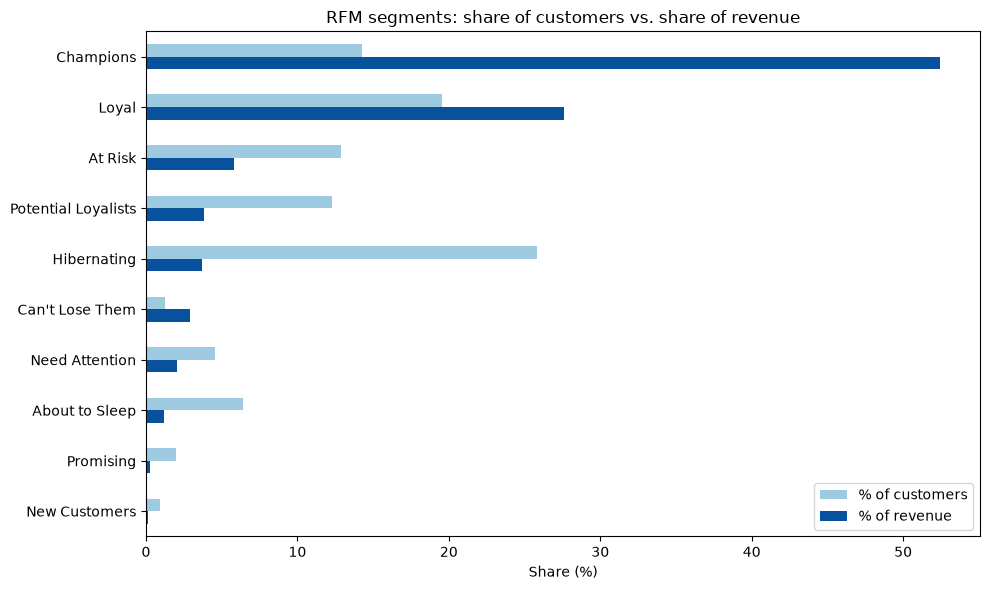

In [15]:
plot_df = seg_summary[["PctCustomers", "PctRevenue"]].mul(100)

ax = plot_df.plot(kind="barh", figsize=(10, 6), color=["#9ecae1", "#08519c"])
ax.invert_yaxis()
ax.set_xlabel("Share (%)")
ax.set_ylabel("")
ax.set_title("RFM segments: share of customers vs. share of revenue")
ax.legend(["% of customers", "% of revenue"])
plt.tight_layout()
plt.savefig("../images/rfm_segments.png", dpi=150, bbox_inches="tight")
plt.show()